# Plant Disease Advisor — Training Notebook

**MCA Major Project (MCA_MP_22), Presidency University, Bengaluru**
Sarthak Vijay · Himanshu Kumar Singh · Arun Das · Sahil Kumar — guide: Ms Lekhya Sree

This notebook **trains the model and saves it**. The app (`app/streamlit_app.py`) then **loads the saved model**.

```
notebooks/train_model.ipynb  ──saves──►  saved_model/plant_model.onnx      (the network)
                                          saved_model/model_info.json       (classes, thresholds, temperature)
app/streamlit_app.py         ──loads──►  saved_model/  (through src/predictor.py)
```

**Where the code lives:** the notebook shows the training. Code that the app also needs (disease table,
image preparation, conformal prediction) is in the `src/` folder, so training and app use *exactly the same* code.

| File | What it does |
|---|---|
| `config.py` | all folder paths and settings |
| `src/disease_info.py` | the 38 classes and their action group (Healthy, Fungal, ...) |
| `src/dataset_split.py` | lists the photos and splits them by leaf |
| `src/image_utils.py` | turns a photo into numbers (same in training and app) |
| `src/leaf_dataset.py` | gives photos to PyTorch during training |
| `src/conformal.py` | temperature, group scores, thresholds, decision |
| `src/metrics.py` | coverage, advice rate, wrong-advice rate (IAR), ECE |
| `src/predictor.py` | loads the saved model and predicts one photo (used by the app) |

**Before you start:** use a GPU. Google Colab: *Runtime → Change runtime type → T4 GPU*.
A full run takes about 1–1.5 hours. Run the cells **from top to bottom**.

## Step 0 — Open the project folder

* **Own computer:** start Jupyter inside the project and open this notebook — nothing to do.
* **Google Colab:** upload `plant_disease_advisor.zip` in the *Files* panel (left side), then run this cell. It unzips the project.
* **Kaggle:** add `plant_disease_advisor.zip` as a dataset; this cell finds it and unzips it.

The cell then makes the project folder the *working folder*, so `import config` and `from src... import ...` work.

In [1]:
import os
import sys
import glob
import zipfile
from pathlib import Path

if os.path.exists("/content"):                     # Google Colab
    base_folder = Path("/content")
    zip_files = glob.glob("/content/plant_disease_advisor*.zip")
elif os.path.exists("/kaggle/working"):            # Kaggle
    base_folder = Path("/kaggle/working")
    zip_files = glob.glob("/kaggle/input/**/plant_disease_advisor*.zip", recursive=True)
else:                                              # own computer
    base_folder = None
    zip_files = []

if base_folder is not None and not (base_folder / "plant_disease_advisor").exists():
    if len(zip_files) == 0:
        raise FileNotFoundError("Upload plant_disease_advisor.zip first (see the note above).")
    zipfile.ZipFile(zip_files[0]).extractall(base_folder)

# find the folder that contains config.py
if base_folder is not None:
    PROJECT_DIR = base_folder / "plant_disease_advisor"
elif Path("config.py").exists():
    PROJECT_DIR = Path.cwd()
else:
    PROJECT_DIR = Path.cwd().parent                # this notebook is inside notebooks/

os.chdir(PROJECT_DIR)
sys.path.insert(0, str(PROJECT_DIR))
print("Project folder:", PROJECT_DIR)

Project folder: /home/claude/plant_disease_advisor


## Step 1 — Install and import libraries
On Colab/Kaggle only four libraries are missing. On your own computer install `requirements-train.txt` first (see README).

In [2]:
# pip skipped in test

In [3]:
import json
import math
import time
import random
import shutil
from collections import Counter
from datetime import date

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import timm
from sklearn.metrics import f1_score, roc_auc_score

# our own project files
import config
from src import disease_info, dataset_split, conformal, metrics
from src.download_data import download_all
from src.image_utils import load_image
from src.leaf_dataset import LeafDataset, train_transform, eval_transform

print("PyTorch", torch.__version__, "| GPU available:", torch.cuda.is_available())

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch 2.14.1+cu130 | GPU available: False


## Step 2 — Settings
Change values **only here**.

* `QUICK_TEST = True` uses a few photos and 1 epoch — just to check that everything runs (≈ 5 min, even on CPU).
  For the real model set it to `False`.
* `FINETUNE_EPOCHS = 0` trains only the last layer (the "frozen backbone" model). Use this if you have **no GPU**.

In [4]:
# ---- model ----
BACKBONE = "mobilenetv3_small_100"     # or "mobilenetv3_small_100" (smaller, faster, a bit less accurate)
PRETRAINED_FILE = "/home/claude/agcp/weights/mobilenetv3_small_100_lamb-266a294c.pth"           # None = download ImageNet weights automatically (needs internet)

# ---- training ----
BATCH_SIZE = 64
HEAD_EPOCHS = 4                  # stage 1: only the new last layer learns
FINETUNE_EPOCHS = 0              # stage 2: the whole network learns (0 = skip, e.g. on CPU)
PATIENCE = 3                     # stop stage 2 if validation F1 does not improve for 3 epochs
LR_STAGE1 = 1e-3                 # learning rate of the new layer in stage 1
LR_HEAD = 3e-4                   # learning rate of the new layer in stage 2
LR_BACKBONE = 3e-5               # learning rate of the pretrained layers in stage 2 (10x smaller)
WEIGHT_DECAY = 0.05
LABEL_SMOOTHING = 0.1

# ---- field re-calibration ----
FIELD_CAL_PER_GROUP = 25         # field photos per group used to set the app's thresholds
RECAL_N = [10, 25, 50]           # experiment: how many field photos are needed?
REPEATS = 20                     # experiment: repeat with different random photos

# ---- other ----
SEED = 42
QUICK_TEST = False
NUM_WORKERS = 0 if os.name == "nt" else 2    # Windows + Jupyter cannot use worker processes

In [5]:
if QUICK_TEST:
    PHOTOS_PER_CLASS = 20        # PlantVillage photos per class
    FIELD_PHOTOS_PER_CLASS = 15  # PlantDoc photos per class
    HEAD_EPOCHS = 1
    FINETUNE_EPOCHS = min(FINETUNE_EPOCHS, 1)
    BATCH_SIZE = 32
    FIELD_CAL_PER_GROUP = 5
    RECAL_N = [5, 10]
    REPEATS = 2
else:
    PHOTOS_PER_CLASS = None      # None = all photos
    FIELD_PHOTOS_PER_CLASS = None

# same random numbers every run -> same results
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
USE_AMP = DEVICE == "cuda"       # mixed precision = faster on GPU
config.OUTPUTS_DIR.mkdir(exist_ok=True)
config.SAVED_MODEL_DIR.mkdir(exist_ok=True)

# short names used in the rest of the notebook
CLASS_NAMES = disease_info.CLASS_NAMES
CLASS_GROUPS = np.array(disease_info.CLASS_GROUPS)
GROUP_CODES = disease_info.GROUP_CODES
NUM_CLASSES = disease_info.NUM_CLASSES     # 38
NUM_GROUPS = disease_info.NUM_GROUPS       # 6
ALPHA = config.ALPHA                       # 0.10

print("Device:", DEVICE, "| quick test:", QUICK_TEST)
if DEVICE == "cpu" and FINETUNE_EPOCHS > 0 and not QUICK_TEST:
    print("WARNING: no GPU. Fine-tuning on CPU takes many hours -> use Colab, or set FINETUNE_EPOCHS = 0.")

Device: cpu | quick test: False


## Step 3 — Download the datasets
Three public datasets from GitHub (about 4 GB). Already downloaded folders are skipped. See `src/download_data.py`.

| Dataset | Photos | What we use it for | Used for training? |
|---|---|---|---|
| **PlantVillage** | 54,305 lab photos, 38 classes | train / val / cal / test | **yes** (train part only) |
| **PlantDoc** | ~2,500 field photos, 28 classes | field test + a few photos to re-calibrate thresholds | **no** |
| **Rice** | 120 photos of a crop we don't have | "can the model say *I don't know*?" | no |

In [6]:
download_all()

PlantVillage already downloaded
PlantDoc already downloaded
Rice photos already downloaded
Datasets are in /home/claude/plant_disease_advisor/data/datasets


## Step 4 — Classes and action groups
Every disease belongs to a **group = what the farmer must do** (see `src/disease_info.py`).

In [7]:
table = []
for name in CLASS_NAMES:
    cause, group_code = disease_info.DISEASES[name]
    table.append({"class": name, "cause": cause, "group": group_code + " " + disease_info.GROUP_NAMES[group_code]})
table = pd.DataFrame(table)
print(table["group"].value_counts().sort_index().to_string())
table.head(10)

group
G0 Healthy                   12
G1 Fungal                    17
G2 Oomycete (late blight)     2
G3 Bacterial                  3
G4 Viral / systemic           3
G5 Pest (mite)                1


,class,cause,group
0,Apple___Apple_scab,Venturia inaequalis (fungus),G1 Fungal
1,Apple___Black_rot,Botryosphaeria obtusa (fungus),G1 Fungal
2,Apple___Cedar_apple_rust,Gymnosporangium juniperi-virginianae (fungus),G1 Fungal
3,Apple___healthy,none,G0 Healthy
4,Blueberry___healthy,none,G0 Healthy
5,Cherry_(including_sour)___Powdery_mildew,Podosphaera clandestina (fungus),G1 Fungal
6,Cherry_(including_sour)___healthy,none,G0 Healthy
7,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_...,Cercospora zeae-maydis (fungus),G1 Fungal
8,Corn_(maize)___Common_rust_,Puccinia sorghi (fungus),G1 Fungal
9,Corn_(maize)___Northern_Leaf_Blight,Exserohilum turcicum (fungus),G1 Fungal


## Step 5 — List PlantVillage photos and split them **by leaf**
PlantVillage photographed each leaf several times. If the same leaf is in training **and** testing, the test score
is too good to be true. So all photos of one leaf go to the same part:
**70 % train · 10 % val · 10 % cal · 10 % test**.

* `train` — the model learns from these
* `val` — picks the best epoch and the temperature
* `cal` — sets the conformal thresholds on lab photos
* `test` — final lab accuracy

In [8]:
start = time.time()
pv_rows = dataset_split.find_plantvillage_images(config.PLANTVILLAGE_DIR, PHOTOS_PER_CLASS)
with_leaf_id = sum(1 for row in pv_rows if row["leaf"] is not None)
print(f"PlantVillage photos: {len(pv_rows):,}  (official leaf id: {with_leaf_id:,})")

pv_rows = dataset_split.fill_missing_leaf_ids(pv_rows)     # pHash grouping for the rest
pv_rows = dataset_split.split_by_leaf(pv_rows, SEED)
print(f"Done in {time.time() - start:.0f} s")

print("Photos per split:", dict(Counter(row["split"] for row in pv_rows)))
print("Leaves found in two splits:", dataset_split.count_leaves_in_two_splits(pv_rows), "(must be 0)")

PlantVillage photos: 54,305  (official leaf id: 41,111)


Done in 36 s
Photos per split: {'train': 38124, 'cal': 5445, 'test': 5334, 'val': 5402}
Leaves found in two splits: 0 (must be 0)


## Step 6 — PlantDoc (field photos) and rice (unknown crop)
PlantDoc folder names are renamed to PlantVillage class names. Some PlantDoc photos exist twice with **two different
labels** — nobody knows the right answer, so they are removed (`keep = False`).

In [9]:
pd_rows_all = dataset_split.find_plantdoc_images(config.PLANTDOC_DIR, FIELD_PHOTOS_PER_CLASS)
pd_rows = [row for row in pd_rows_all if row["keep"]]
rice_rows = dataset_split.find_rice_images(config.RICE_DIR)

print(f"PlantDoc photos: {len(pd_rows_all):,}  removed (conflicting copies): {len(pd_rows_all) - len(pd_rows)}  used: {len(pd_rows):,}")
print(f"Rice photos: {len(rice_rows)}")

# save the photo lists for the report
pd.DataFrame(pv_rows).to_csv(config.OUTPUTS_DIR / "photos_plantvillage.csv", index=False)
pd.DataFrame(pd_rows_all).to_csv(config.OUTPUTS_DIR / "photos_plantdoc.csv", index=False)

field_groups = CLASS_GROUPS[[row["label"] for row in pd_rows]]
for g in range(NUM_GROUPS):
    print(f"  {GROUP_CODES[g]} {disease_info.GROUP_NAMES[GROUP_CODES[g]]:24s} {np.sum(field_groups == g):5d} field photos")

PlantDoc photos: 2,578  removed (conflicting copies): 64  used: 2,514
Rice photos: 120


  G0 Healthy                    850 field photos
  G1 Fungal                    1159 field photos
  G2 Oomycete (late blight)     199 field photos
  G3 Bacterial                  177 field photos
  G4 Viral / systemic           127 field photos
  G5 Pest (mite)                  2 field photos


### Look at the data: this is the **lab-to-field shift**
Top row: lab photos (one leaf, plain background). Bottom row: field photos (many leaves, soil, hands, shadows).

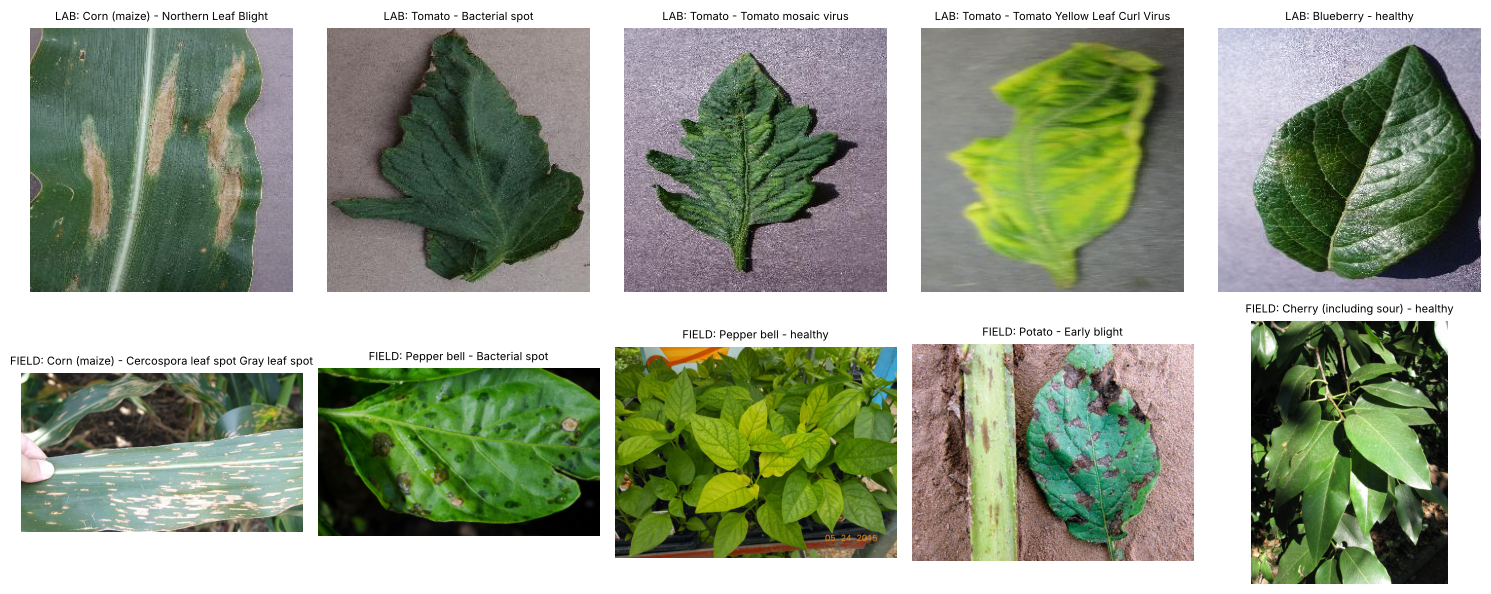

In [10]:
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
lab_examples = random.Random(1).sample(pv_rows, 5)
field_examples = random.Random(1).sample(pd_rows, 5)
for i in range(5):
    axes[0, i].imshow(load_image(lab_examples[i]["path"]))
    axes[0, i].set_title("LAB: " + disease_info.pretty_class_name(lab_examples[i]["class_name"]), fontsize=8)
    axes[1, i].imshow(load_image(field_examples[i]["path"]))
    axes[1, i].set_title("FIELD: " + disease_info.pretty_class_name(field_examples[i]["class_name"]), fontsize=8)
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.show()

## Step 7 — Data loaders
A `DataLoader` gives the model photos in small batches.
* **train** photos get random changes (crop, flip, rotation, colour) → `train_transform` in `src/leaf_dataset.py`
* all other photos use `eval_transform` = `prepare_image()` from `src/image_utils.py` — **the same function the app uses**

In [11]:
train_rows = [row for row in pv_rows if row["split"] == "train"]
val_rows = [row for row in pv_rows if row["split"] == "val"]


def make_loader(rows, transform, shuffle):
    dataset = LeafDataset(rows, transform)
    return torch.utils.data.DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=shuffle, drop_last=shuffle,
                                       num_workers=NUM_WORKERS, pin_memory=(DEVICE == "cuda"))


train_loader = make_loader(train_rows, train_transform, shuffle=True)
print(f"Training photos: {len(train_rows):,}  |  validation photos: {len(val_rows):,}  |  batches per epoch: {len(train_loader)}")

Training photos: 38,124  |  validation photos: 5,402  |  batches per epoch: 595


## Step 8 — Build the model layer by layer
Like `model.add(...)` in Keras, we stack three layers:
1. **backbone** — a network pretrained on ImageNet (1.2 million photos). It turns a photo into a list of numbers ("features").
2. **dropout** — during training randomly switches off 20 % of the features, so the model does not rely on just a few.
3. **classifier** — a new layer that gives one score (logit) for each of our 38 classes.

In [12]:
# Layer 1: the pretrained backbone. num_classes=0 removes its old 1000-class ImageNet layer.
backbone = timm.create_model(BACKBONE, pretrained=(PRETRAINED_FILE is None), num_classes=0)

# Only for a computer without internet: load the ImageNet weights from a file.
if PRETRAINED_FILE is not None:
    backbone.load_state_dict(torch.load(PRETRAINED_FILE, map_location="cpu"), strict=False)

# How many features does the backbone give per photo? Send one blank photo through it and look.
backbone.eval()
with torch.no_grad():
    blank_photo = torch.zeros(1, 3, config.IMAGE_SIZE, config.IMAGE_SIZE)
    num_features = backbone(blank_photo).shape[1]
print("Features per photo:", num_features)

Features per photo: 1024


In [13]:
model = nn.Sequential()
model.add_module("backbone", backbone)                                  # layer 1: photo -> features
model.add_module("dropout", nn.Dropout(p=0.2))                           # layer 2: dropout
model.add_module("classifier", nn.Linear(num_features, NUM_CLASSES))     # layer 3: features -> 38 scores
model = model.to(DEVICE)

total_parameters = sum(p.numel() for p in model.parameters())
print(model.classifier)
print(f"{total_parameters / 1e6:.1f} million parameters, on {DEVICE}")

Linear(in_features=1024, out_features=38, bias=True)
1.6 million parameters, on cpu


## Step 9 — Training helpers
* **Loss** = cross-entropy with *label smoothing 0.1* (the model is told "95 % sure" instead of "100 % sure" → less over-confident).
* **Optimizer** = AdamW. **Scheduler** = the learning rate starts small (warm-up), then falls smoothly (cosine).
* After every epoch we measure **macro-F1** on the validation photos and keep the best weights.

In [14]:
def train_one_epoch(optimizer, scheduler, scaler, backbone_frozen):
    model.train()
    if backbone_frozen:
        model.backbone.eval()          # frozen backbone: keep its BatchNorm statistics as they are
    losses = []
    for images, labels in train_loader:
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)
        with torch.autocast(device_type="cuda", enabled=USE_AMP):
            outputs = model(images)
            loss = F.cross_entropy(outputs, labels, label_smoothing=LABEL_SMOOTHING)
        optimizer.zero_grad()
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()
        losses.append(loss.item())
    return float(np.mean(losses))


def predict_logits(rows):
    # runs the model on a list of photos and returns the logits (photos x 38) as numpy
    model.eval()
    all_logits = []
    with torch.no_grad():
        for images, _ in make_loader(rows, eval_transform, shuffle=False):
            with torch.autocast(device_type="cuda", enabled=USE_AMP):
                logits = model(images.to(DEVICE))
            all_logits.append(logits.float().cpu().numpy())
    return np.concatenate(all_logits)


def validation_f1():
    predictions = predict_logits(val_rows).argmax(axis=1)
    labels = [row["label"] for row in val_rows]
    return f1_score(labels, predictions, average="macro")


def make_scheduler(optimizer, epochs, warmup_epochs):
    total_steps = epochs * len(train_loader)
    if warmup_epochs == 0:
        return torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=total_steps)
    warmup_steps = warmup_epochs * len(train_loader)
    warmup = torch.optim.lr_scheduler.LinearLR(optimizer, start_factor=1 / warmup_steps, total_iters=warmup_steps)
    cosine = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=max(1, total_steps - warmup_steps))
    return torch.optim.lr_scheduler.SequentialLR(optimizer, [warmup, cosine], milestones=[warmup_steps])


history = []        # one line per epoch
best_f1 = -1.0
best_weights = None

## Step 10 — Stage 1: train only the new last layer
The pretrained backbone is **frozen** (its weights do not change). Only `model.classifier` learns.

In [15]:
for p in model.parameters():
    p.requires_grad = False
for p in model.classifier.parameters():
    p.requires_grad = True

optimizer = torch.optim.AdamW(model.classifier.parameters(), lr=LR_STAGE1, weight_decay=WEIGHT_DECAY)
scheduler = make_scheduler(optimizer, HEAD_EPOCHS, warmup_epochs=0)
scaler = torch.amp.GradScaler(enabled=USE_AMP)

for epoch in range(HEAD_EPOCHS):
    start = time.time()
    loss = train_one_epoch(optimizer, scheduler, scaler, backbone_frozen=True)
    f1 = validation_f1()
    history.append({"stage": 1, "epoch": epoch + 1, "loss": loss, "val_f1": f1})
    print(f"[stage 1] epoch {epoch + 1}/{HEAD_EPOCHS}  loss {loss:.4f}  val macro-F1 {f1:.4f}  ({time.time() - start:.0f} s)")
    if f1 > best_f1:
        best_f1 = f1
        best_weights = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

[stage 1] epoch 1/4  loss 1.2597  val macro-F1 0.9006  (317 s)


[stage 1] epoch 2/4  loss 1.0365  val macro-F1 0.9062  (306 s)


[stage 1] epoch 3/4  loss 0.9987  val macro-F1 0.9202  (295 s)


[stage 1] epoch 4/4  loss 0.9905  val macro-F1 0.9212  (308 s)


## Step 11 — Stage 2: fine-tune the whole network
Everything learns now, but the pretrained layers get a **10× smaller learning rate** so they change only gently.
Skipped when `FINETUNE_EPOCHS = 0`.

In [16]:
if FINETUNE_EPOCHS > 0:
    for p in model.parameters():
        p.requires_grad = True

    optimizer = torch.optim.AdamW([
        {"params": model.backbone.parameters(), "lr": LR_BACKBONE},
        {"params": model.classifier.parameters(), "lr": LR_HEAD},
    ], weight_decay=WEIGHT_DECAY)
    scheduler = make_scheduler(optimizer, FINETUNE_EPOCHS, warmup_epochs=1)
    scaler = torch.amp.GradScaler(enabled=USE_AMP)

    epochs_without_improvement = 0
    for epoch in range(FINETUNE_EPOCHS):
        start = time.time()
        loss = train_one_epoch(optimizer, scheduler, scaler, backbone_frozen=False)
        f1 = validation_f1()
        history.append({"stage": 2, "epoch": epoch + 1, "loss": loss, "val_f1": f1})
        print(f"[stage 2] epoch {epoch + 1}/{FINETUNE_EPOCHS}  loss {loss:.4f}  val macro-F1 {f1:.4f}  ({time.time() - start:.0f} s)")
        if f1 > best_f1:
            best_f1 = f1
            best_weights = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement >= PATIENCE:
                print("Stopping early: validation F1 stopped improving.")
                break

model.load_state_dict(best_weights)       # keep the best epoch
print(f"Best validation macro-F1: {best_f1:.4f}")

Best validation macro-F1: 0.9212


## Step 12 — Run the model once on every photo
All the next steps only need the model's **logits**, so we compute them once.

In [17]:
start = time.time()
logits_pv = predict_logits(pv_rows)        # all PlantVillage photos
logits_pd = predict_logits(pd_rows)        # PlantDoc photos we keep
logits_rice = predict_logits(rice_rows)    # rice photos
print(f"Done in {time.time() - start:.0f} s")

pv_labels = np.array([row["label"] for row in pv_rows])
pv_split = np.array([row["split"] for row in pv_rows])
pd_labels = np.array([row["label"] for row in pd_rows])
pd_dup = np.array([row["dup_group"] for row in pd_rows])
is_val, is_cal, is_test = pv_split == "val", pv_split == "cal", pv_split == "test"

Done in 300 s


## Step 13 — Accuracy and temperature scaling
**Softmax** turns logits into probabilities. **Temperature scaling** divides all logits by one number *T* so the
confidence becomes honest (found on validation photos; `conformal.fit_temperature`). It never changes the predicted class.
**ECE** = gap between confidence and accuracy (0 = perfect).

In [18]:
T = conformal.fit_temperature(logits_pv[is_val], pv_labels[is_val])
probs_pv = conformal.softmax(logits_pv, T)
probs_pd = conformal.softmax(logits_pd, T)

lab_pred = probs_pv[is_test].argmax(axis=1)
field_pred = probs_pd.argmax(axis=1)

scores = {
    "temperature": T,
    "lab_accuracy": float(np.mean(lab_pred == pv_labels[is_test])),
    "lab_macro_f1": float(f1_score(pv_labels[is_test], lab_pred, average="macro")),
    "field_accuracy": float(np.mean(field_pred == pd_labels)),
    "field_macro_f1": float(f1_score(pd_labels, field_pred, average="macro", labels=sorted(set(pd_labels)))),
    "field_group_accuracy": float(np.mean(CLASS_GROUPS[field_pred] == CLASS_GROUPS[pd_labels])),
    "field_mean_confidence": float(probs_pd.max(axis=1).mean()),
    "lab_ece": metrics.expected_calibration_error(probs_pv[is_test], pv_labels[is_test]),
    "field_ece": metrics.expected_calibration_error(probs_pd, pd_labels),
}
pd.Series(scores).round(4)

temperature              0.4900
lab_accuracy             0.9363
lab_macro_f1             0.9264
field_accuracy           0.2124
field_macro_f1           0.1945
field_group_accuracy     0.5461
field_mean_confidence    0.6352
lab_ece                  0.0101
field_ece                0.4228
dtype: float64

Look at **field accuracy** vs **field mean confidence**: on field photos the model is far more confident than it is
correct. That is why we cannot trust its top-1 answer for advice — next step.

## Step 14 — Action-group conformal prediction (our method)
(code: `src/conformal.py`)
1. **Group probability** = sum of the probabilities of the classes in that group.
2. **Score** $s(x,g) = 1 - \text{group probability}$ (small = likely).
3. **One threshold per group** $\hat q_g$ = the $\lceil (n_g+1)(1-\alpha)\rceil$-th smallest score of calibration photos of group $g$.
4. **Prediction set** = all groups with $s(x,g) \le \hat q_g$. Contains the true group ≥ 90 % of the time for every group
   — *if* calibration and test photos look alike.
5. **Decision:** 1 group → advise · 2+ groups → refer to KVK · 0 groups → unknown.

We compare with **Top-1** (always advise the group of the most likely class) and **APS → groups** (the standard conformal method on classes).

In [19]:
def calibrate(probs, labels, fallback=None):
    # thresholds for our method + the APS baseline, from one set of calibration photos
    fallback_thresholds = None if fallback is None else fallback["group_thresholds"]
    return {
        "group_thresholds": conformal.calibrate_group_thresholds(probs, labels, CLASS_GROUPS, NUM_GROUPS,
                                                                 ALPHA, fallback_thresholds),
        "aps_threshold": conformal.calibrate_aps(probs, labels, ALPHA),
    }


def evaluate(calibration, probs, labels):
    # coverage / advice rate / IAR of the three methods on a set of test photos
    sets = {
        "Top-1": conformal.top1_sets(probs, CLASS_GROUPS, NUM_GROUPS),
        "APS → groups": conformal.aps_group_sets(probs, CLASS_GROUPS, NUM_GROUPS, calibration["aps_threshold"]),
        "Action-group (ours)": conformal.prediction_sets(probs, CLASS_GROUPS, NUM_GROUPS, calibration["group_thresholds"]),
    }
    results = {}
    for method, method_sets in sets.items():
        results[method] = metrics.advisory_metrics(method_sets, labels, CLASS_GROUPS, GROUP_CODES)
    return results


lab_calibration = calibrate(probs_pv[is_cal], pv_labels[is_cal])
results_lab = evaluate(lab_calibration, probs_pv[is_test], pv_labels[is_test])
results_field_lab_thresholds = evaluate(lab_calibration, probs_pd, pd_labels)

pd.concat({"lab → lab test": pd.DataFrame(results_lab).T,
           "lab → FIELD test": pd.DataFrame(results_field_lab_thresholds).T}).round(3)

coverage  set_size  advice_rate    IAR  \
lab → lab test   Top-1                   0.954     1.000        1.000  0.046   
                 APS → groups            1.000     3.559        0.216  0.001   
                 Action-group (ours)     0.898     0.919        0.916  0.021   
lab → FIELD test Top-1                   0.546     1.000        1.000  0.454   
                 APS → groups            0.997     5.139        0.007  0.056   
                 Action-group (ours)     0.391     0.725        0.722  0.460   

                                      wrong_advice_all  coverage_G0  \
lab → lab test   Top-1                           0.046        0.993   
                 APS → groups                    0.000        1.000   
                 Action-group (ours)             0.019        0.893   
lab → FIELD test Top-1                           0.454        0.378   
                 APS → groups                    0.000        1.000   
                 Action-group (ours)             0.332        0.086   

                                      coverage_G1  coverage_G2  coverage_G3  \
lab → lab test   Top-1                      0.942        0.793        0.948   
                 APS → groups               1.000        0.997        1.000   
                 Action-group (ours)        0.909        0.872        0.905   
lab → FIELD test Top-1                      0.752        0.683        0.085   
                 APS → groups               0.999        1.000        0.983   
                 Action-group (ours)        0.656        0.734        0.017   

                                      coverage_G4  coverage_G5  
lab → lab test   Top-1                      0.973        0.884  
                 APS → groups               1.000        1.000  
                 Action-group (ours)        0.876        0.982  
lab → FIELD test Top-1                      0.228        0.000  
                 APS → groups               0.984        0.000  
                 Action-group (ours)        0.000        0.000

**How to read it:** on lab photos the coverage of our method is ≈ 0.90, as promised. On field photos with the
*lab* thresholds it collapses — the promise only holds when photos look alike. Next we repair it.

## Step 15 — Field re-calibration: how many field photos are needed?
We take **n labelled field photos per group**, recompute only the thresholds (no re-training), and test on the
other field photos. Repeated with different random photos and averaged. Copies of a photo (`dup_group`) always stay
on the same side. A group with too few field photos keeps its lab threshold.

In [20]:
pd_groups = CLASS_GROUPS[pd_labels]


def pick_field_calibration_photos(n_per_group, seed):
    # True = calibration photo, False = test photo
    rng = np.random.default_rng(seed)
    chosen = []
    for g in sorted(set(pd_groups)):
        dup_groups = sorted(set(pd_dup[pd_groups == g]))
        rng.shuffle(dup_groups)
        picked = 0
        for dup_group in dup_groups:
            photos_left = np.sum(pd_groups == g) - picked
            if picked >= n_per_group or photos_left <= 10:     # keep at least 10 photos per group for testing
                break
            indices = np.nonzero(pd_dup == dup_group)[0]
            chosen.extend(indices.tolist())
            picked += len(indices)
    mask = np.zeros(len(pd_labels), dtype=bool)
    mask[chosen] = True
    return mask


recalibration_results = {}
for n in RECAL_N:
    runs = []
    for repeat in range(REPEATS):
        cal_mask = pick_field_calibration_photos(n, seed=1000 * n + repeat)
        field_calibration = calibrate(probs_pd[cal_mask], pd_labels[cal_mask], fallback=lab_calibration)
        runs.append(evaluate(field_calibration, probs_pd[~cal_mask], pd_labels[~cal_mask]))
    # average over the repeats
    averaged = {}
    for method in runs[0]:
        averaged[method] = {}
        for metric in runs[0][method]:
            averaged[method][metric] = float(np.nanmean([run[method][metric] for run in runs]))
    recalibration_results[n] = averaged

pd.concat({f"n = {n}": pd.DataFrame(v).T for n, v in recalibration_results.items()}).round(3)

coverage  set_size  advice_rate    IAR  \
n = 10 Top-1                   0.548     1.000        1.000  0.452   
       APS → groups            0.997     5.210        0.006  0.058   
       Action-group (ours)     0.894     3.240        0.088  0.173   
n = 25 Top-1                   0.552     1.000        1.000  0.448   
       APS → groups            0.996     5.120        0.009  0.062   
       Action-group (ours)     0.926     3.380        0.091  0.158   
n = 50 Top-1                   0.560     1.000        1.000  0.440   
       APS → groups            0.997     5.062        0.010  0.045   
       Action-group (ours)     0.904     3.127        0.129  0.188   

                            wrong_advice_all  coverage_G0  coverage_G1  \
n = 10 Top-1                           0.452        0.378        0.752   
       APS → groups                    0.000        1.000        0.999   
       Action-group (ours)             0.017        0.901        0.890   
n = 25 Top-1                           0.448        0.378        0.753   
       APS → groups                    0.000        1.000        0.999   
       Action-group (ours)             0.015        0.926        0.930   
n = 50 Top-1                           0.440        0.378        0.753   
       APS → groups                    0.000        1.000        0.999   
       Action-group (ours)             0.025        0.894        0.916   

                            coverage_G2  coverage_G3  coverage_G4  coverage_G5  
n = 10 Top-1                      0.681        0.084        0.232        0.000  
       APS → groups               1.000        0.976        0.985        0.275  
       Action-group (ours)        0.904        0.901        0.872        0.000  
n = 25 Top-1                      0.683        0.084        0.225        0.000  
       APS → groups               1.000        0.971        0.986        0.125  
       Action-group (ours)        0.935        0.915        0.903        0.000  
n = 50 Top-1                      0.676        0.086        0.233        0.000  
       APS → groups               1.000        0.968        0.989        0.000  
       Action-group (ours)        0.895        0.888        0.908        0.000

## Step 16 — Final thresholds for the app + "unknown photo" gate
* The app gets thresholds from `FIELD_CAL_PER_GROUP` field photos per group (the photos users send look like field photos).
* The **energy score** is low for familiar photos and high for strange ones. The cut-off keeps 95 % of the field
  calibration photos; anything above it is answered with "photo not recognised".
* We then test this final system on the field photos that were **not** used for calibration.

In [21]:
final_cal_mask = pick_field_calibration_photos(FIELD_CAL_PER_GROUP, seed=SEED)
final_calibration = calibrate(probs_pd[final_cal_mask], pd_labels[final_cal_mask], fallback=lab_calibration)
group_thresholds = np.minimum(final_calibration["group_thresholds"], 1.0)    # a score is never above 1

energy_field_cal = conformal.energy_score(logits_pd[final_cal_mask], T)
energy_threshold = float(np.quantile(energy_field_cal, 0.95))

# final system on the field test photos
test_mask = ~final_cal_mask
final_results = evaluate(final_calibration, probs_pd[test_mask], pd_labels[test_mask])

# energy gate: how well does it catch rice photos?
energy_lab = conformal.energy_score(logits_pv[is_test], T)
energy_field_test = conformal.energy_score(logits_pd[test_mask], T)
energy_rice = conformal.energy_score(logits_rice, T)
unknown_results = {
    "energy_threshold": energy_threshold,
    "rice_flagged_unknown": float(np.mean(energy_rice > energy_threshold)),
    "field_test_flagged_unknown": float(np.mean(energy_field_test > energy_threshold)),
    "lab_test_flagged_unknown": float(np.mean(energy_lab > energy_threshold)),
    "auroc_lab_vs_rice": float(roc_auc_score(np.r_[np.ones(len(energy_rice)), np.zeros(len(energy_lab))],
                                             np.r_[energy_rice, energy_lab])),
}
print("Thresholds per group:", {GROUP_CODES[g]: round(float(group_thresholds[g]), 4) for g in range(NUM_GROUPS)})
display(pd.Series(unknown_results).round(3))
pd.DataFrame(final_results).T.round(3)

Thresholds per group: {'G0': 0.9892, 'G1': 0.7161, 'G2': 0.9846, 'G3': 0.9999, 'G4': 0.9993, 'G5': 0.8963}


energy_threshold             -1.177
rice_flagged_unknown          0.000
field_test_flagged_unknown    0.080
lab_test_flagged_unknown      0.013
auroc_lab_vs_rice             0.855
dtype: float64

,coverage,set_size,advice_rate,IAR,wrong_advice_all,coverage_G0,coverage_G1,coverage_G2,coverage_G3,coverage_G4,coverage_G5
Top-1,0.551,1.000,1.000,0.449,0.449,0.379,0.750,0.684,0.079,0.216,0.0
APS → groups,0.997,5.242,0.003,0.125,0.000,1.000,0.999,1.000,0.980,0.980,0.0
Action-group (ours),0.894,3.373,0.083,0.212,0.018,0.919,0.852,0.971,0.974,0.922,0.0


## Step 17 — Figures

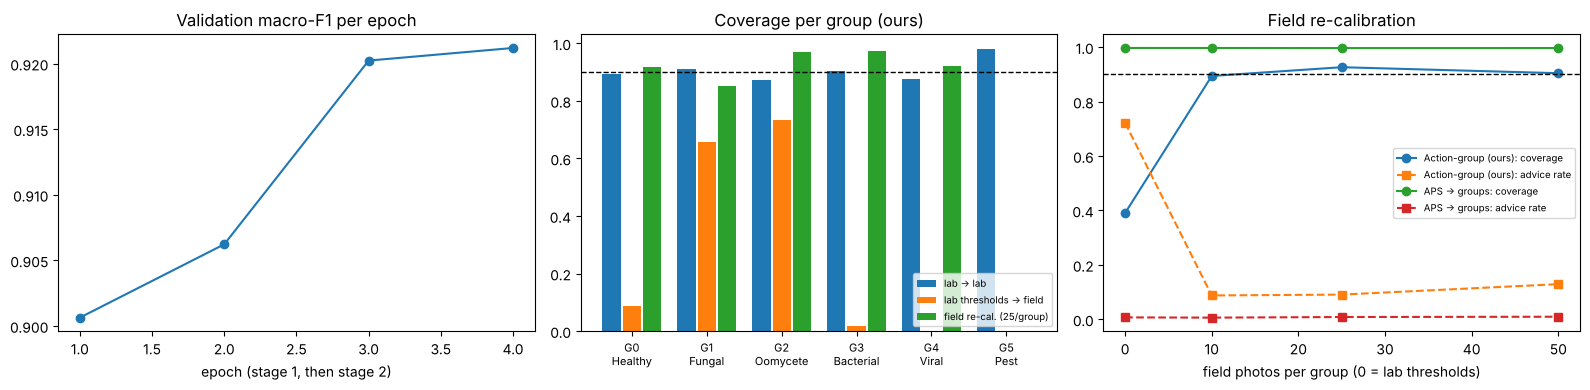

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# 1) validation F1 per epoch
axes[0].plot(range(1, len(history) + 1), [h["val_f1"] for h in history], "-o")
axes[0].set_title("Validation macro-F1 per epoch")
axes[0].set_xlabel("epoch (stage 1, then stage 2)")

# 2) coverage per group, our method
group_labels = [f"{code}\n{disease_info.GROUP_NAMES[code].split(' ')[0]}" for code in GROUP_CODES]
bars = [("lab → lab", results_lab), ("lab thresholds → field", results_field_lab_thresholds),
        (f"field re-cal. ({FIELD_CAL_PER_GROUP}/group)", final_results)]
width = 0.27
for k, (label, result) in enumerate(bars):
    heights = [result["Action-group (ours)"][f"coverage_{code}"] for code in GROUP_CODES]
    axes[1].bar(np.arange(NUM_GROUPS) + (k - 1) * width, np.nan_to_num(heights), width * 0.9, label=label)
axes[1].axhline(1 - ALPHA, color="black", linestyle="--", linewidth=1)
axes[1].set_xticks(range(NUM_GROUPS))
axes[1].set_xticklabels(group_labels, fontsize=8)
axes[1].set_title("Coverage per group (ours)")
axes[1].legend(fontsize=7)

# 3) how many field photos are needed
x_values = [0] + RECAL_N
for method in ["Action-group (ours)", "APS → groups"]:
    coverage = [results_field_lab_thresholds[method]["coverage"]] + [recalibration_results[n][method]["coverage"] for n in RECAL_N]
    advice = [results_field_lab_thresholds[method]["advice_rate"]] + [recalibration_results[n][method]["advice_rate"] for n in RECAL_N]
    axes[2].plot(x_values, coverage, "-o", label=method + ": coverage")
    axes[2].plot(x_values, advice, "--s", label=method + ": advice rate")
axes[2].axhline(1 - ALPHA, color="black", linestyle="--", linewidth=1)
axes[2].set_xlabel("field photos per group (0 = lab thresholds)")
axes[2].set_title("Field re-calibration")
axes[2].legend(fontsize=7)

plt.tight_layout()
plt.savefig(config.OUTPUTS_DIR / "results.png", dpi=150)
plt.show()

## Step 18 — SAVE the model for the app
Three files go into `saved_model/`:

| File | What | Who uses it |
|---|---|---|
| `plant_model.onnx` | the trained network in ONNX format (runs without PyTorch) | the app |
| `model_info.json` | class names, groups, temperature, thresholds, energy cut-off, scores | the app |
| `plant_model.pt` | PyTorch weights | only if you want to train further |

ONNX is a standard file format for neural networks. The app runs it with `onnxruntime`, so the app does **not**
need PyTorch (this also avoids the Windows PyTorch DLL problem).

In [23]:
model_cpu = model.to("cpu").float().eval()
torch.save({"backbone": BACKBONE, "state_dict": model_cpu.state_dict(), "class_names": CLASS_NAMES},
           config.PYTORCH_WEIGHTS_FILE)

example_photo = torch.randn(1, 3, config.IMAGE_SIZE, config.IMAGE_SIZE)
export_settings = dict(input_names=["image"], output_names=["logits"],
                       dynamic_axes={"image": {0: "batch"}, "logits": {0: "batch"}}, opset_version=17)
try:
    torch.onnx.export(model_cpu, example_photo, config.MODEL_FILE, dynamo=False, **export_settings)
except TypeError:                     # older PyTorch has no `dynamo` option
    torch.onnx.export(model_cpu, example_photo, config.MODEL_FILE, **export_settings)

model_info = {
    "backbone": BACKBONE,
    "trained_on": str(date.today()),
    "quick_test": QUICK_TEST,
    "finetuned": FINETUNE_EPOCHS > 0,
    "class_names": CLASS_NAMES,
    "class_groups": CLASS_GROUPS.tolist(),
    "group_codes": GROUP_CODES,
    "temperature": T,
    "alpha": ALPHA,
    "group_thresholds": [float(x) for x in group_thresholds],                                   # used by the app
    "group_thresholds_lab": [float(min(x, 1.0)) for x in lab_calibration["group_thresholds"]],  # for reference
    "energy_threshold": energy_threshold,
    "image_size": config.IMAGE_SIZE,
    "resize_size": config.RESIZE_SIZE,
    "scores": {**scores,
               "field_coverage": final_results["Action-group (ours)"]["coverage"],
               "field_advice_rate": final_results["Action-group (ours)"]["advice_rate"],
               "field_IAR": final_results["Action-group (ours)"]["IAR"],
               "field_IAR_top1": final_results["Top-1"]["IAR"]},
}
with open(config.MODEL_INFO_FILE, "w") as file:
    json.dump(model_info, file, indent=1)

for path in [config.MODEL_FILE, config.MODEL_INFO_FILE, config.PYTORCH_WEIGHTS_FILE]:
    print(f"saved {path.relative_to(PROJECT_DIR)}  ({path.stat().st_size / 1e6:.1f} MB)")

/tmp/ipykernel_344/2983041707.py:9: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(model_cpu, example_photo, config.MODEL_FILE, dynamo=False, **export_settings)


saved saved_model/plant_model.onnx  (6.2 MB)
saved saved_model/model_info.json  (0.0 MB)
saved saved_model/plant_model.pt  (6.4 MB)


In [24]:
# all results for the report / paper
def to_plain(value):
    # numpy numbers and NaN -> normal Python values that JSON accepts
    if isinstance(value, dict):
        return {str(k): to_plain(v) for k, v in value.items()}
    if isinstance(value, list):
        return [to_plain(v) for v in value]
    if isinstance(value, (str, bool)) or value is None:
        return value
    number = float(value)
    return None if math.isnan(number) else number


all_results = {"settings": {"backbone": BACKBONE, "quick_test": QUICK_TEST, "head_epochs": HEAD_EPOCHS,
                            "finetune_epochs": FINETUNE_EPOCHS, "seed": SEED, "alpha": ALPHA},
               "history": history, "scores": scores,
               "lab_to_lab": results_lab, "lab_thresholds_to_field": results_field_lab_thresholds,
               "field_recalibration": recalibration_results, "final_system_field_test": final_results,
               "unknown_photo_gate": unknown_results}
with open(config.OUTPUTS_DIR / "results.json", "w") as file:
    json.dump(to_plain(all_results), file, indent=1)
print("saved outputs/results.json")

saved outputs/results.json


## Step 19 — Test the saved model **exactly like the app does**
We load `saved_model/` with `src/predictor.py` — the same class the app uses — and check:
1. ONNX gives the same logits as PyTorch,
2. a field photo gets a sensible answer.

In [25]:
from src.predictor import PlantDiseasePredictor
from src.image_utils import prepare_image

predictor = PlantDiseasePredictor()

photo = load_image(pd_rows[0]["path"])
onnx_logits = predictor.session.run(None, {"image": prepare_image(photo)[np.newaxis]})[0]
with torch.no_grad():
    torch_logits = model_cpu(torch.from_numpy(prepare_image(photo))[None]).numpy()
print(f"largest difference ONNX vs PyTorch: {np.abs(onnx_logits - torch_logits).max():.1e}  (should be < 1e-3)")

result = predictor.predict(photo)
print("true class :", pd_rows[0]["class_name"])
print("decision   :", result["decision"], "|", result["advised_group"])
print("set        :", result["prediction_set"])
print("top class  :", result["top_classes"][0]["pretty_name"], f"{result['top_classes'][0]['probability']:.2f}")
print("advice     :", result["advice"]["what_to_do"][:120], "...")

largest difference ONNX vs PyTorch: 7.4e-06  (should be < 1e-3)
true class : Apple___Apple_scab
decision   : refer | None
set        : ['Fungal', 'Bacterial']
top class  : Strawberry - Leaf scorch 0.89
advice     : Take the leaf (or clear photos of it) to your nearest Krishi Vigyan Kendra (KVK) or agriculture officer. Do not spray an ...


## Step 20 — Use the model in the app
On **Colab** download the trained model (the cell below makes `saved_model.zip`), unzip it into the project's
`saved_model/` folder on your computer, then in a terminal inside the project folder:

```
pip install -r requirements.txt
streamlit run app/streamlit_app.py
```
The browser opens the app. Upload a leaf photo.

In [26]:
zip_path = shutil.make_archive(str(PROJECT_DIR / "saved_model"), "zip", config.SAVED_MODEL_DIR)
print("Created", zip_path)
try:
    from google.colab import files     # only exists on Colab
    files.download(zip_path)
except ImportError:
    pass

Created /home/claude/plant_disease_advisor/saved_model.zip


## Check your understanding
1. In Step 14 the coverage is ≈ 0.90 on lab photos but much lower on field photos. Which assumption of conformal
   prediction is broken, and why does Step 15 repair it *without* re-training the network?
2. Why does `pick_field_calibration_photos` keep copies of the same photo (`dup_group`) on one side?
   What would happen to the measured coverage if it did not?
3. A photo gets the set {Fungal, Bacterial}. Why is "refer to KVK" safer than advising the more likely group?

**Exercise:** change `ALPHA` to 0.20 and run Steps 14–16 again. Write down what happens to coverage, set size,
advice rate and IAR, and explain the trade-off.